PATH CHECKS

In [1]:
from pathlib import Path

import cv2
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from tqdm.auto import tqdm


# Folder containing all creator directories.
DATA_ROOT = Path(
    "/mnt/storage/data/youtube/updated_75users/daily"
)

# Separate writable location for analysis outputs.
OUTPUT_DIR = (
    Path("/home/ganand/Documents/Youtube-Persistence/Code")
    / "Data Analysis/Results"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

INVENTORY_CSV = OUTPUT_DIR / "all_creators_video_inventory.csv"
SUMMARY_CSV = OUTPUT_DIR / "creator_summary.csv"

print("Data folder exists:", DATA_ROOT.exists())
print("Data folder:", repr(str(DATA_ROOT)))
print("Output folder exists:", OUTPUT_DIR.exists())
print("Output folder:", repr(str(OUTPUT_DIR)))

if not DATA_ROOT.is_dir():
    raise FileNotFoundError(f"Data folder does not exist: {DATA_ROOT}")

Data folder exists: True
Data folder: '/mnt/storage/data/youtube/updated_75users/daily'
Output folder exists: True
Output folder: '/home/ganand/Documents/Youtube-Persistence/Code/Data Analysis/Results'


In [2]:
write_test = OUTPUT_DIR / "_write_test.txt"

write_test.write_text("Write access works.", encoding="utf-8")

print("Write succeeded:", write_test.exists())
print("Test path:", repr(str(write_test)))

write_test.unlink(missing_ok=True)

Write succeeded: True
Test path: '/home/ganand/Documents/Youtube-Persistence/Code/Data Analysis/Results/_write_test.txt'


In [3]:
VIDEO_EXTENSIONS = {
    ".mp4",
    ".mov",
    ".avi",
    ".mkv",
    ".webm",
    ".m4v",
    ".mpeg",
    ".mpg",
}

# Find every directory named "mp4" beneath the daily directory.
mp4_directories = sorted(
    path
    for path in DATA_ROOT.rglob("mp4")
    if path.is_dir()
)

video_items = []

for mp4_directory in mp4_directories:
    creator = mp4_directory.parent.name

    for video_path in mp4_directory.rglob("*"):
        if (
            video_path.is_file()
            and video_path.suffix.lower() in VIDEO_EXTENSIONS
        ):
            video_items.append((creator, video_path))

print(f"MP4 directories found: {len(mp4_directories):,}")
print(f"Videos found: {len(video_items):,}")

if not video_items:
    raise RuntimeError(f"No videos found under {DATA_ROOT}")

MP4 directories found: 68
Videos found: 2,872


VIDEO ANALYSIS / INSPECTION

In [4]:
def inspect_video(creator: str, video_path: Path) -> dict:
    result = {
        "creator": creator,
        "filename": video_path.name,
        "relative_path": str(video_path.relative_to(DATA_ROOT)),
        "extension": video_path.suffix.lower(),
        "size_mb": None,
        "width": None,
        "height": None,
        "resolution": None,
        "fps": None,
        "frame_count": None,
        "duration_seconds": None,
        "duration_minutes": None,
        "codec": None,
        "metadata_readable": False,
        "error": None,
    }

    capture = None

    try:
        result["size_mb"] = round(
            video_path.stat().st_size / (1024 ** 2),
            2,
        )

        capture = cv2.VideoCapture(str(video_path))

        if not capture.isOpened():
            result["error"] = "OpenCV could not open the video"
            return result

        width = int(capture.get(cv2.CAP_PROP_FRAME_WIDTH))
        height = int(capture.get(cv2.CAP_PROP_FRAME_HEIGHT))
        fps = float(capture.get(cv2.CAP_PROP_FPS))
        frame_count = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
        fourcc = int(capture.get(cv2.CAP_PROP_FOURCC))

        duration_seconds = (
            frame_count / fps
            if fps > 0 and frame_count > 0
            else None
        )

        codec = "".join(
            chr((fourcc >> (8 * index)) & 0xFF)
            for index in range(4)
        ).replace("\x00", "").strip()

        result.update({
            "width": width if width > 0 else None,
            "height": height if height > 0 else None,
            "resolution": (
                f"{width}x{height}"
                if width > 0 and height > 0
                else None
            ),
            "fps": round(fps, 3) if fps > 0 else None,
            "frame_count": frame_count if frame_count > 0 else None,
            "duration_seconds": (
                round(duration_seconds, 2)
                if duration_seconds is not None
                else None
            ),
            "duration_minutes": (
                round(duration_seconds / 60, 2)
                if duration_seconds is not None
                else None
            ),
            "codec": codec or None,
            "metadata_readable": True,
        })

    except Exception as exc:
        result["error"] = f"{type(exc).__name__}: {exc}"

    finally:
        if capture is not None:
            capture.release()

    return result

In [5]:
records = [
    inspect_video(creator, video_path)
    for creator, video_path in tqdm(
        video_items,
        desc="Inspecting all videos",
    )
]

inventory = pd.DataFrame(records)
inventory.to_csv(INVENTORY_CSV, index=False)

print(f"Videos analyzed: {len(inventory):,}")
print("CSV saved:", INVENTORY_CSV.exists())
print("Path:", repr(str(INVENTORY_CSV)))

Inspecting all videos:   0%|          | 0/2872 [00:00<?, ?it/s]

Videos analyzed: 2,872
CSV saved: True
Path: '/home/ganand/Documents/Youtube-Persistence/Code/Data Analysis/Results/all_creators_video_inventory.csv'


OVERVIEW

In [6]:
inventory = pd.read_csv(INVENTORY_CSV)

total_videos = len(inventory)
total_size_gb = inventory["size_mb"].fillna(0).sum() / 1024
total_duration_hours = (
    inventory["duration_seconds"].fillna(0).sum() / 3600
)
readable_count = inventory["metadata_readable"].fillna(False).sum()

print(f"Total videos:        {total_videos:,}")
print(f"Readable metadata:   {int(readable_count):,}")
print(f"Total size:          {total_size_gb:,.2f} GB")
print(f"Total duration:      {total_duration_hours:,.2f} hours")
print(
    f"Average duration:    "
    f"{inventory['duration_minutes'].mean():,.2f} minutes"
)
print(
    f"Median duration:     "
    f"{inventory['duration_minutes'].median():,.2f} minutes"
)

Total videos:        2,872
Readable metadata:   2,872
Total size:          639.67 GB
Total duration:      459.37 hours
Average duration:    9.60 minutes
Median duration:     7.60 minutes


In [7]:
print("Video codecs:")
display(
    inventory["codec"]
    .fillna("Unknown")
    .value_counts()
    .to_frame("video_count")
)

print("Video resolutions:")
display(
    inventory["resolution"]
    .fillna("Unknown")
    .value_counts()
    .head(20)
    .to_frame("video_count")
)

print("Files with metadata errors:")
display(
    inventory.loc[
        inventory["error"].notna(),
        ["creator", "filename", "codec", "error"],
    ]
)

Video codecs:


,video_count
codec,
h264,2530
VP90,228
AV01,114


Video resolutions:


,video_count
resolution,
1920x1080,2153
3840x2160,218
720x1280,108
1280x720,106
1080x1920,95
1920x960,81
1280x716,53
1920x888,10
1080x1080,10


Files with metadata errors:


,creator,filename,codec,error


In [8]:
from pathlib import Path
import pandas as pd
from IPython.display import display

OUTPUT_DIR = (
    Path("/home/ganand/Documents/Youtube-Persistence/Code")
    / "Data Analysis/Results"
)

INVENTORY_CSV = OUTPUT_DIR / "all_creators_video_inventory.csv"

inventory = pd.read_csv(INVENTORY_CSV)

total_videos = len(inventory)
total_creators = inventory["creator"].nunique()
total_size_gb = inventory["size_mb"].fillna(0).sum() / 1024
total_duration_hours = (
    inventory["duration_seconds"].fillna(0).sum() / 3600
)

average_duration = inventory["duration_minutes"].mean()
median_duration = inventory["duration_minutes"].median()
minimum_duration = inventory["duration_minutes"].min()
maximum_duration = inventory["duration_minutes"].max()

missing_duration = inventory["duration_minutes"].isna().sum()
missing_resolution = inventory["resolution"].isna().sum()
metadata_errors = inventory["error"].notna().sum()

dataset_overview = pd.DataFrame({
    "Metric": [
        "Total creators",
        "Total videos",
        "Total storage size (GB)",
        "Total video duration (hours)",
        "Average video duration (minutes)",
        "Median video duration (minutes)",
        "Shortest video (minutes)",
        "Longest video (minutes)",
        "Videos missing duration",
        "Videos missing resolution",
        "Videos with metadata errors",
    ],
    "Value": [
        total_creators,
        total_videos,
        round(total_size_gb, 2),
        round(total_duration_hours, 2),
        round(average_duration, 2),
        round(median_duration, 2),
        round(minimum_duration, 2),
        round(maximum_duration, 2),
        missing_duration,
        missing_resolution,
        metadata_errors,
    ],
})

display(dataset_overview)

,Metric,Value
0,Total creators,68.00
1,Total videos,2872.00
2,Total storage size (GB),639.67
3,Total video duration (hours),459.37
4,Average video duration (minutes),9.60
5,Median video duration (minutes),7.60
6,Shortest video (minutes),0.13
7,Longest video (minutes),51.16
8,Videos missing duration,0.00
9,Videos missing resolution,0.00


In [9]:
OVERVIEW_CSV = OUTPUT_DIR / "dataset_overview.csv"

dataset_overview.to_csv(OVERVIEW_CSV, index=False)

print("Saved:", OVERVIEW_CSV.exists())
print("Path:", repr(str(OVERVIEW_CSV)))

Saved: True
Path: '/home/ganand/Documents/Youtube-Persistence/Code/Data Analysis/Results/dataset_overview.csv'


CREATOR SUMMARY / DISTRIBUTION

In [10]:
creator_summary = (
    inventory.groupby("creator", as_index=False)
    .agg(
        video_count=("filename", "size"),
        total_duration_minutes=("duration_minutes", "sum"),
        average_duration_minutes=("duration_minutes", "mean"),
        median_duration_minutes=("duration_minutes", "median"),
        total_size_mb=("size_mb", "sum"),
    )
)

creator_summary["total_duration_hours"] = (
    creator_summary["total_duration_minutes"] / 60
)

creator_summary["total_size_gb"] = (
    creator_summary["total_size_mb"] / 1024
)

creator_summary["video_percentage"] = (
    creator_summary["video_count"]
    / creator_summary["video_count"].sum()
    * 100
)

creator_summary["duration_percentage"] = (
    creator_summary["total_duration_minutes"]
    / creator_summary["total_duration_minutes"].sum()
    * 100
)

creator_summary = creator_summary[
    [
        "creator",
        "video_count",
        "video_percentage",
        "total_duration_hours",
        "duration_percentage",
        "average_duration_minutes",
        "median_duration_minutes",
        "total_size_gb",
    ]
].sort_values(
    "video_count",
    ascending=False,
)

numeric_columns = creator_summary.columns.drop("creator")
creator_summary[numeric_columns] = (
    creator_summary[numeric_columns].round(2)
)

display(creator_summary)

,creator,video_count,video_percentage,total_duration_hours,duration_percentage,average_duration_minutes,median_duration_minutes,total_size_gb
50,RosetheLourdes,114,3.97,29.67,6.46,15.61,14.97,35.66
63,What Rissa Knows,105,3.66,15.12,3.29,8.64,8.38,14.19
39,Matt Svatos,102,3.55,13.43,2.92,7.90,7.59,13.90
9,BEEF1776,99,3.45,26.80,5.83,16.24,14.50,32.41
27,Jake Bender,94,3.27,11.26,2.45,7.19,6.47,12.34
...,...,...,...,...,...,...,...,...
48,Reek Jones,7,0.24,1.28,0.28,10.95,10.65,1.56
65,cooper konopaski,7,0.24,0.95,0.21,8.16,7.87,1.42
67,kellie paige,7,0.24,1.28,0.28,10.98,10.55,1.34
44,NENE’S MUNCHIES,6,0.21,2.22,0.48,22.25,23.91,3.99


In [11]:
CREATOR_SUMMARY_CSV = OUTPUT_DIR / "creator_distribution.csv"

creator_summary.to_csv(CREATOR_SUMMARY_CSV, index=False)

print("Saved:", CREATOR_SUMMARY_CSV.exists())
print("Path:", repr(str(CREATOR_SUMMARY_CSV)))

Saved: True
Path: '/home/ganand/Documents/Youtube-Persistence/Code/Data Analysis/Results/creator_distribution.csv'


In [12]:
creator_summary.sort_values("video_count").head(10)

,creator,video_count,video_percentage,total_duration_hours,duration_percentage,average_duration_minutes,median_duration_minutes,total_size_gb
41,Misha,2,0.07,0.19,0.04,5.84,5.84,0.08
44,NENE’S MUNCHIES,6,0.21,2.22,0.48,22.25,23.91,3.99
48,Reek Jones,7,0.24,1.28,0.28,10.95,10.65,1.56
67,kellie paige,7,0.24,1.28,0.28,10.98,10.55,1.34
65,cooper konopaski,7,0.24,0.95,0.21,8.16,7.87,1.42
23,FitwithToshu,8,0.28,0.38,0.08,2.86,1.82,0.57
8,Azula Jean Vlogs,9,0.31,2.66,0.58,17.74,16.47,2.37
40,Millicent,9,0.31,3.59,0.78,23.93,25.97,5.12
18,Dakota Williams,10,0.35,0.80,0.17,4.80,5.05,0.95
26,Hunter Fulop,10,0.35,1.00,0.22,6.03,6.02,4.37


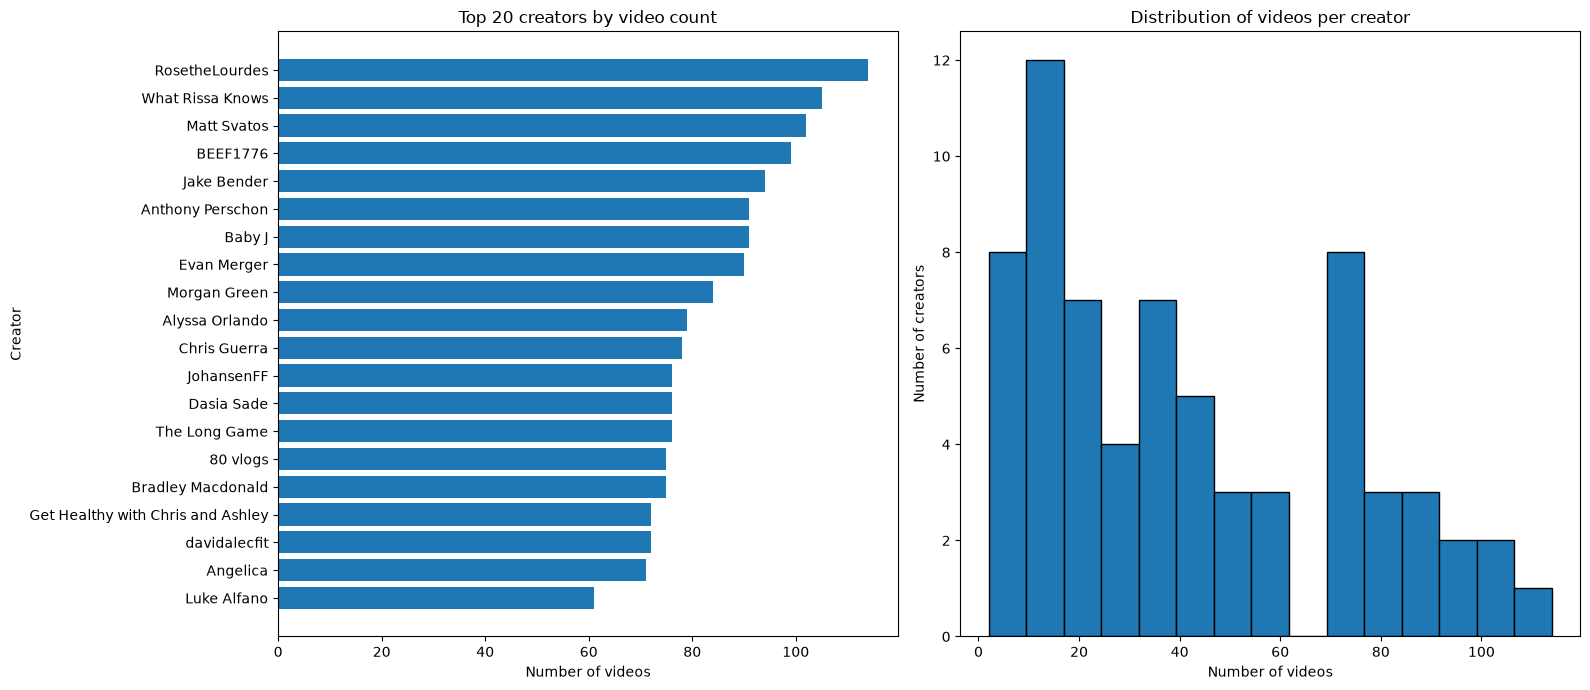

Chart saved: '/home/ganand/Documents/Youtube-Persistence/Code/Data Analysis/Results/creator_distribution.png'


In [13]:
import matplotlib.pyplot as plt

top_20 = creator_summary.head(20).sort_values(
    "video_count",
    ascending=True,
)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].barh(
    top_20["creator"],
    top_20["video_count"],
)

axes[0].set_title("Top 20 creators by video count")
axes[0].set_xlabel("Number of videos")
axes[0].set_ylabel("Creator")

axes[1].hist(
    creator_summary["video_count"],
    bins=15,
    edgecolor="black",
)

axes[1].set_title("Distribution of videos per creator")
axes[1].set_xlabel("Number of videos")
axes[1].set_ylabel("Number of creators")

plt.tight_layout()

CREATOR_CHART = OUTPUT_DIR / "creator_distribution.png"
plt.savefig(CREATOR_CHART, dpi=200, bbox_inches="tight")
plt.show()

print("Chart saved:", repr(str(CREATOR_CHART)))

QUALITY / FORMAT / RESOLUTION CHECKS

In [14]:
quality_data = inventory.copy()

quality_data["codec_clean"] = (
    quality_data["codec"]
    .fillna("Unknown")
    .astype(str)
    .str.strip()
    .str.upper()
)

quality_data["resolution_clean"] = (
    quality_data["resolution"]
    .fillna("Unknown")
    .astype(str)
)

quality_data["fps_rounded"] = quality_data["fps"].round(2)

In [15]:
quality_summary = pd.DataFrame({
    "Check": [
        "Total videos",
        "Missing file size",
        "Missing duration",
        "Missing width",
        "Missing height",
        "Missing resolution",
        "Missing FPS",
        "Missing codec",
        "Metadata errors",
    ],
    "Video count": [
        len(quality_data),
        quality_data["size_mb"].isna().sum(),
        quality_data["duration_minutes"].isna().sum(),
        quality_data["width"].isna().sum(),
        quality_data["height"].isna().sum(),
        quality_data["resolution"].isna().sum(),
        quality_data["fps"].isna().sum(),
        quality_data["codec"].isna().sum(),
        quality_data["error"].notna().sum(),
    ],
})

quality_summary["Percentage"] = (
    quality_summary["Video count"]
    / len(quality_data)
    * 100
).round(2)

display(quality_summary)

,Check,Video count,Percentage
0,Total videos,2872,100.0
1,Missing file size,0,0.0
2,Missing duration,0,0.0
3,Missing width,0,0.0
4,Missing height,0,0.0
5,Missing resolution,0,0.0
6,Missing FPS,0,0.0
7,Missing codec,0,0.0
8,Metadata errors,0,0.0


In [16]:
codec_summary = (
    quality_data.groupby("codec_clean", as_index=False)
    .agg(video_count=("filename", "size"))
    .sort_values("video_count", ascending=False)
)

codec_summary["percentage"] = (
    codec_summary["video_count"]
    / codec_summary["video_count"].sum()
    * 100
).round(2)

display(codec_summary)

,codec_clean,video_count,percentage
1,H264,2530,88.09
2,VP90,228,7.94
0,AV01,114,3.97


In [17]:
def classify_codec(codec):
    codec = str(codec).upper()

    if "AV01" in codec or codec == "AV1":
        return "AV1 — decoder check required"

    if codec in {"H264", "AVC1", "X264"}:
        return "H.264 — broadly supported"

    if codec in {"HEVC", "H265", "HEV1", "HVC1"}:
        return "HEVC/H.265 — decoder check required"

    if codec in {"VP09", "VP9"}:
        return "VP9 — usually software decoded"

    if codec == "UNKNOWN":
        return "Unknown codec"

    return "Other codec — review"


quality_data["codec_category"] = (
    quality_data["codec_clean"].apply(classify_codec)
)

display(
    quality_data["codec_category"]
    .value_counts()
    .to_frame("video_count")
)

,video_count
codec_category,
H.264 — broadly supported,2530
Other codec — review,228
AV1 — decoder check required,114


In [18]:
resolution_summary = (
    quality_data.groupby("resolution_clean", as_index=False)
    .agg(video_count=("filename", "size"))
    .sort_values("video_count", ascending=False)
)

resolution_summary["percentage"] = (
    resolution_summary["video_count"]
    / resolution_summary["video_count"].sum()
    * 100
).round(2)

display(resolution_summary.head(20))

,resolution_clean,video_count,percentage
11,1920x1080,2153,74.97
19,3840x2160,218,7.59
23,720x1280,108,3.76
7,1280x720,106,3.69
3,1080x1920,95,3.31
13,1920x960,81,2.82
6,1280x716,53,1.85
1,1080x1080,10,0.35
12,1920x888,10,0.35
0,1078x1920,6,0.21


In [19]:
def classify_resolution(row):
    width = row["width"]
    height = row["height"]

    if pd.isna(width) or pd.isna(height):
        return "Unknown"

    largest_dimension = max(width, height)
    smallest_dimension = min(width, height)

    if largest_dimension >= 3840 or smallest_dimension >= 2160:
        return "4K or higher"

    if largest_dimension >= 1920 or smallest_dimension >= 1080:
        return "1080p"

    if largest_dimension >= 1280 or smallest_dimension >= 720:
        return "720p"

    if largest_dimension >= 854 or smallest_dimension >= 480:
        return "480p"

    return "Below 480p"


quality_data["resolution_category"] = quality_data.apply(
    classify_resolution,
    axis=1,
)

resolution_category_summary = (
    quality_data["resolution_category"]
    .value_counts()
    .to_frame("video_count")
)

display(resolution_category_summary)

,video_count
resolution_category,
1080p,2373
720p,268
4K or higher,222
Below 480p,5
480p,4


In [20]:
fps_summary = (
    quality_data.groupby("fps_rounded", dropna=False)
    .agg(video_count=("filename", "size"))
    .reset_index()
    .sort_values("video_count", ascending=False)
)

fps_summary["percentage"] = (
    fps_summary["video_count"]
    / fps_summary["video_count"].sum()
    * 100
).round(2)

display(fps_summary.head(20))

,fps_rounded,video_count,percentage
49,30.00,1319,45.93
48,29.97,570,19.85
4,24.00,316,11.00
53,60.00,213,7.42
52,59.94,152,5.29
10,25.00,115,4.00
3,23.98,92,3.20
45,29.94,8,0.28
46,29.95,7,0.24
39,29.88,5,0.17


In [21]:
unusual_fps = quality_data.loc[
    quality_data["fps"].notna()
    & (
        (quality_data["fps"] < 20)
        | (quality_data["fps"] > 61)
    ),
    [
        "creator",
        "filename",
        "fps",
        "resolution",
        "codec",
    ],
].sort_values("fps")

print(f"Videos with unusual frame rates: {len(unusual_fps):,}")
display(unusual_fps.head(30))

Videos with unusual frame rates: 2


,creator,filename,fps,resolution,codec
754,Bradley Macdonald,66 - Day 71_75 Hard - Burpees for 45 min??.mp4,18.0,3840x2160,VP90
759,Bradley Macdonald,34 - Day 55_75 Hard - First OUTDOOR ride of th...,18.0,3840x2160,VP90


In [22]:
quality_summary.to_csv(
    OUTPUT_DIR / "video_quality_summary.csv",
    index=False,
)

codec_summary.to_csv(
    OUTPUT_DIR / "codec_summary.csv",
    index=False,
)

resolution_summary.to_csv(
    OUTPUT_DIR / "resolution_summary.csv",
    index=False,
)

fps_summary.to_csv(
    OUTPUT_DIR / "fps_summary.csv",
    index=False,
)

unusual_fps.to_csv(
    OUTPUT_DIR / "unusual_frame_rates.csv",
    index=False,
)

print("Quality tables saved successfully.")

Quality tables saved successfully.


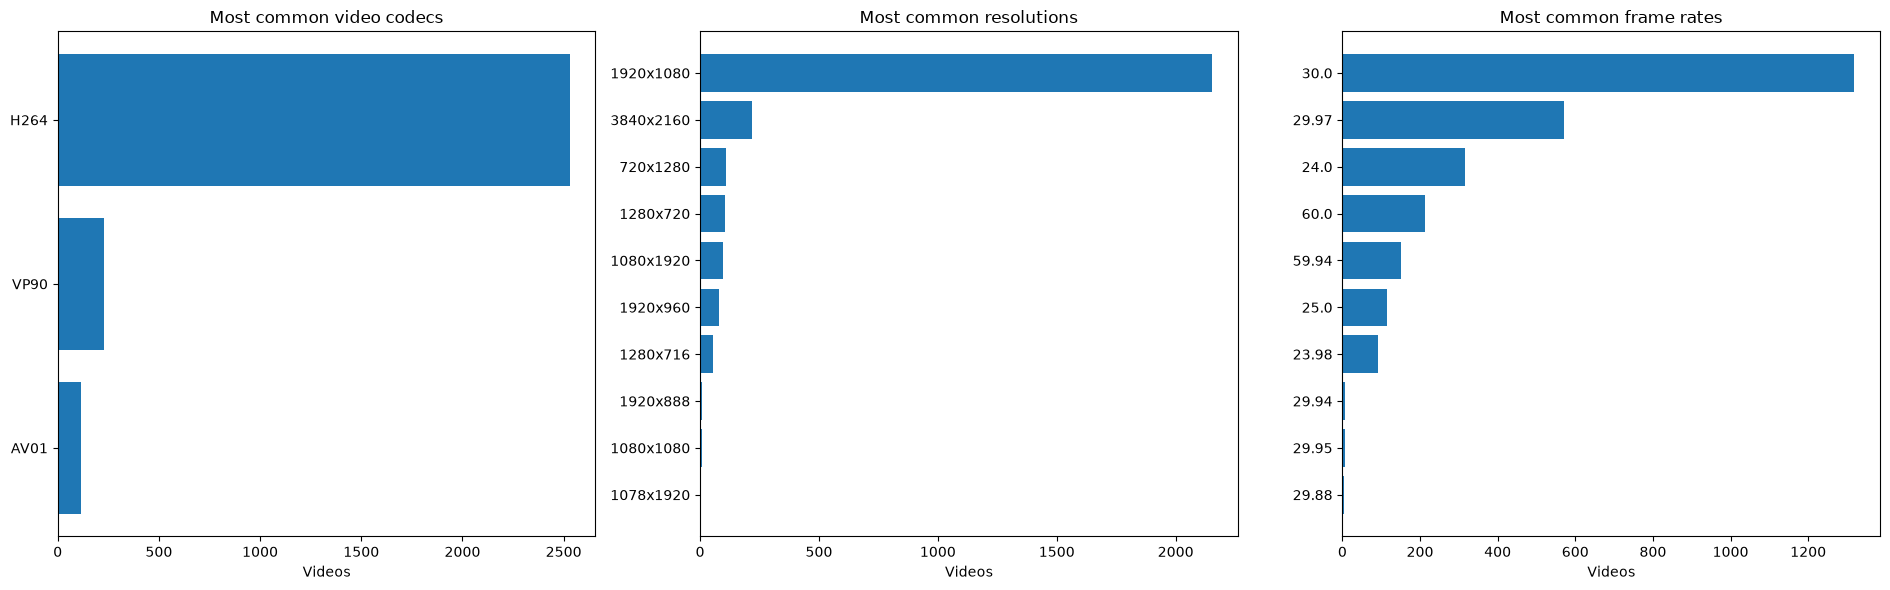

Chart saved: '/home/ganand/Documents/Youtube-Persistence/Code/Data Analysis/Results/video_quality_and_consistency.png'


In [23]:
fig, axes = plt.subplots(1, 3, figsize=(19, 6))

codec_plot = codec_summary.head(10).sort_values(
    "video_count"
)

axes[0].barh(
    codec_plot["codec_clean"],
    codec_plot["video_count"],
)
axes[0].set_title("Most common video codecs")
axes[0].set_xlabel("Videos")

resolution_plot = resolution_summary.head(10).sort_values(
    "video_count"
)

axes[1].barh(
    resolution_plot["resolution_clean"],
    resolution_plot["video_count"],
)
axes[1].set_title("Most common resolutions")
axes[1].set_xlabel("Videos")

fps_plot = fps_summary.dropna(
    subset=["fps_rounded"]
).head(10).sort_values("video_count")

axes[2].barh(
    fps_plot["fps_rounded"].astype(str),
    fps_plot["video_count"],
)
axes[2].set_title("Most common frame rates")
axes[2].set_xlabel("Videos")

plt.tight_layout()

QUALITY_CHART = OUTPUT_DIR / "video_quality_and_consistency.png"
plt.savefig(QUALITY_CHART, dpi=200, bbox_inches="tight")
plt.show()

print("Chart saved:", repr(str(QUALITY_CHART)))

OUTLIER / DUPLICATES DETECTION

In [24]:
def calculate_iqr_bounds(series):
    values = series.dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = max(0, q1 - 1.5 * iqr)
    upper_bound = q3 + 1.5 * iqr

    return q1, q3, lower_bound, upper_bound


duration_bounds = calculate_iqr_bounds(
    inventory["duration_minutes"]
)

size_bounds = calculate_iqr_bounds(
    inventory["size_mb"]
)

duration_q1, duration_q3, duration_low, duration_high = (
    duration_bounds
)

size_q1, size_q3, size_low, size_high = size_bounds

print("Duration thresholds")
print(f"Q1: {duration_q1:.2f} minutes")
print(f"Q3: {duration_q3:.2f} minutes")
print(f"Lower threshold: {duration_low:.2f} minutes")
print(f"Upper threshold: {duration_high:.2f} minutes")

print("\nFile-size thresholds")
print(f"Q1: {size_q1:.2f} MB")
print(f"Q3: {size_q3:.2f} MB")
print(f"Lower threshold: {size_low:.2f} MB")
print(f"Upper threshold: {size_high:.2f} MB")

Duration thresholds
Q1: 4.39 minutes
Q3: 12.20 minutes
Lower threshold: 0.00 minutes
Upper threshold: 23.91 minutes

File-size thresholds
Q1: 82.82 MB
Q3: 267.07 MB
Lower threshold: 0.00 MB
Upper threshold: 543.44 MB


In [25]:
outlier_data = inventory.copy()

outlier_data["duration_outlier"] = (
    outlier_data["duration_minutes"].notna()
    & (
        (outlier_data["duration_minutes"] < duration_low)
        | (outlier_data["duration_minutes"] > duration_high)
    )
)

outlier_data["size_outlier"] = (
    outlier_data["size_mb"].notna()
    & (
        (outlier_data["size_mb"] < size_low)
        | (outlier_data["size_mb"] > size_high)
    )
)

outlier_data["invalid_duration"] = (
    outlier_data["duration_seconds"].notna()
    & (outlier_data["duration_seconds"] <= 0)
)

outlier_data["unusual_fps"] = (
    outlier_data["fps"].notna()
    & (
        (outlier_data["fps"] < 20)
        | (outlier_data["fps"] > 61)
    )
)

outlier_data["missing_essential_metadata"] = (
    outlier_data[
        [
            "duration_seconds",
            "width",
            "height",
            "fps",
        ]
    ]
    .isna()
    .any(axis=1)
)

In [26]:
def get_outlier_reasons(row):
    reasons = []

    if row["duration_outlier"]:
        reasons.append("Unusual duration")

    if row["size_outlier"]:
        reasons.append("Unusual file size")

    if row["invalid_duration"]:
        reasons.append("Invalid duration")

    if row["unusual_fps"]:
        reasons.append("Unusual frame rate")

    if row["missing_essential_metadata"]:
        reasons.append("Missing metadata")

    return "; ".join(reasons)


outlier_data["outlier_reason"] = outlier_data.apply(
    get_outlier_reasons,
    axis=1,
)

outliers = outlier_data.loc[
    outlier_data["outlier_reason"] != "",
    [
        "creator",
        "filename",
        "relative_path",
        "size_mb",
        "duration_minutes",
        "resolution",
        "fps",
        "codec",
        "outlier_reason",
    ],
].sort_values(
    ["creator", "filename"]
)

print(f"Videos with at least one outlier flag: {len(outliers):,}")
display(outliers.head(30))

Videos with at least one outlier flag: 308


,creator,filename,relative_path,size_mb,duration_minutes,resolution,fps,codec,outlier_reason
29,80 vlogs,Day_58 - 52 - Replacing The Break Pads | 75 HA...,80 vlogs/mp4/Day_58 - 52 - Replacing The Break...,965.38,30.38,1920x1080,29.970,h264,Unusual duration; Unusual file size
127,Alex Eubank,003_Day_03 - Alex Eubank_ARMS WITH MY DAD ｜ 75...,Alex Eubank/mp4/003_Day_03 - Alex Eubank_ARMS ...,1245.31,24.04,3840x2160,59.940,AV01,Unusual duration; Unusual file size
128,Alex Eubank,005_Day_05 - 01 - Day 5.mp4,Alex Eubank/mp4/005_Day_05 - 01 - Day 5.mp4,1123.10,17.66,3840x2160,59.940,AV01,Unusual file size
119,Alex Eubank,006_Day_06 - 02 - Day 6.mp4,Alex Eubank/mp4/006_Day_06 - 02 - Day 6.mp4,772.09,12.08,3840x2160,59.940,AV01,Unusual file size
116,Alex Eubank,008_Alex Eubank_One Of My Worst Moments ｜ 75 H...,Alex Eubank/mp4/008_Alex Eubank_One Of My Wors...,980.96,15.83,3840x2160,59.940,AV01,Unusual file size
124,Alex Eubank,009_Alex Eubank_I'm Where I Belong ｜ 75 Hard E...,Alex Eubank/mp4/009_Alex Eubank_I'm Where I Be...,871.94,13.83,3840x2160,59.940,AV01,Unusual file size
117,Alex Eubank,010_Alex Eubank_This City Needs Me ｜ 75 Hard E...,Alex Eubank/mp4/010_Alex Eubank_This City Need...,882.64,13.10,3840x2160,59.940,AV01,Unusual file size
118,Alex Eubank,012_Alex Eubank_CRASH OUT ｜ Ep. 12.mp4,Alex Eubank/mp4/012_Alex Eubank_CRASH OUT ｜ Ep...,836.24,10.80,3840x2160,59.940,AV01,Unusual file size
111,Alex Eubank,013_Day_13 - Alex Eubank_We got sick.. getting...,Alex Eubank/mp4/013_Day_13 - Alex Eubank_We go...,1112.79,18.46,3840x2160,59.940,AV01,Unusual file size
110,Alex Eubank,014_Alex Eubank_Peak Crashout ｜ 75 Hard Ep. 14...,Alex Eubank/mp4/014_Alex Eubank_Peak Crashout ...,650.44,15.58,3840x2160,29.970,AV01,Unusual file size


In [27]:
outlier_summary = pd.DataFrame({
    "Outlier type": [
        "Unusual duration",
        "Unusual file size",
        "Invalid duration",
        "Unusual frame rate",
        "Missing essential metadata",
    ],
    "Video count": [
        outlier_data["duration_outlier"].sum(),
        outlier_data["size_outlier"].sum(),
        outlier_data["invalid_duration"].sum(),
        outlier_data["unusual_fps"].sum(),
        outlier_data["missing_essential_metadata"].sum(),
    ],
})

outlier_summary["Percentage"] = (
    outlier_summary["Video count"]
    / len(outlier_data)
    * 100
).round(2)

display(outlier_summary)

,Outlier type,Video count,Percentage
0,Unusual duration,194,6.75
1,Unusual file size,254,8.84
2,Invalid duration,0,0.00
3,Unusual frame rate,2,0.07
4,Missing essential metadata,0,0.00


In [28]:
duplicate_names = (
    inventory.loc[
        inventory.duplicated(
            subset=["filename"],
            keep=False,
        )
    ]
    .sort_values("filename")
)

print(
    "Rows with duplicate filenames:",
    len(duplicate_names),
)

display(
    duplicate_names[
        [
            "creator",
            "filename",
            "relative_path",
            "size_mb",
            "duration_minutes",
        ]
    ].head(30)
)

Rows with duplicate filenames: 0


,creator,filename,relative_path,size_mb,duration_minutes


In [29]:
duplicate_signature_columns = [
    "size_mb",
    "duration_seconds",
    "resolution",
]

possible_duplicates = (
    inventory.dropna(
        subset=duplicate_signature_columns
    )
    .loc[
        lambda frame: frame.duplicated(
            subset=duplicate_signature_columns,
            keep=False,
        )
    ]
    .sort_values(duplicate_signature_columns)
)

print(
    "Possible duplicate rows:",
    len(possible_duplicates),
)

display(
    possible_duplicates[
        [
            "creator",
            "filename",
            "relative_path",
            "size_mb",
            "duration_seconds",
            "resolution",
        ]
    ].head(30)
)

Possible duplicate rows: 125


,creator,filename,relative_path,size_mb,duration_seconds,resolution
575,Baby J,Day_71 - Baby J_Becoming HER： Day 71 of My 75 ...,Baby J/mp4/Day_71 - Baby J_Becoming HER： Day 7...,2.11,19.07,1080x1920
619,Baby J,Day_71 - Baby J_Becoming HER- Day 71 of My 75 ...,Baby J/mp4/Day_71 - Baby J_Becoming HER- Day 7...,2.11,19.07,1080x1920
2043,Nat Rosch,05 - 75 HARD DAY 2 - showing up even when i do...,Nat Rosch /mp4/duplicates_backup/05 - 75 HARD ...,49.82,120.00,1920x1080
2046,Nat Rosch,03 - 75 HARD DAY 2 - showing up even when i do...,Nat Rosch /mp4/duplicates_backup/03 - 75 HARD ...,49.82,120.00,1920x1080
782,Brandon Eastman,12 - Post Malone - Enough Is Enough (Acoustic ...,Brandon Eastman/mp4/12 - Post Malone - Enough ...,53.72,174.77,1080x1080
788,Brandon Eastman,15 - Post Malone - Enough Is Enough (Acoustic ...,Brandon Eastman/mp4/duplicates_backup/15 - Pos...,53.72,174.77,1080x1080
784,Brandon Eastman,14 - Post Malone - Enough Is Enough (Acoustic ...,Brandon Eastman/mp4/duplicates_backup/14 - Pos...,68.06,171.37,932x1920
785,Brandon Eastman,28 - Post Malone - Enough Is Enough (Acoustic ...,Brandon Eastman/mp4/duplicates_backup/28 - Pos...,68.06,171.37,932x1920
626,Baby J,Day_31 - 28 - 🔥 Day 31 of 75 HARD - 10-Min Sta...,Baby J/mp4/Day_31 - 28 - 🔥 Day 31 of 75 HARD -...,71.49,403.27,1280x720
640,Baby J,29 - 🔥 Day 31 of 75 HARD - 10-Min StairMaster ...,Baby J/mp4/duplicates_backup/29 - 🔥 Day 31 of ...,71.49,403.27,1280x720


In [30]:
outlier_summary.to_csv(
    OUTPUT_DIR / "outlier_summary.csv",
    index=False,
)

outliers.to_csv(
    OUTPUT_DIR / "video_outliers.csv",
    index=False,
)

duplicate_names.to_csv(
    OUTPUT_DIR / "duplicate_filename_candidates.csv",
    index=False,
)

possible_duplicates.to_csv(
    OUTPUT_DIR / "possible_duplicate_videos.csv",
    index=False,
)

print("Outlier and duplicate-candidate files saved.")

Outlier and duplicate-candidate files saved.


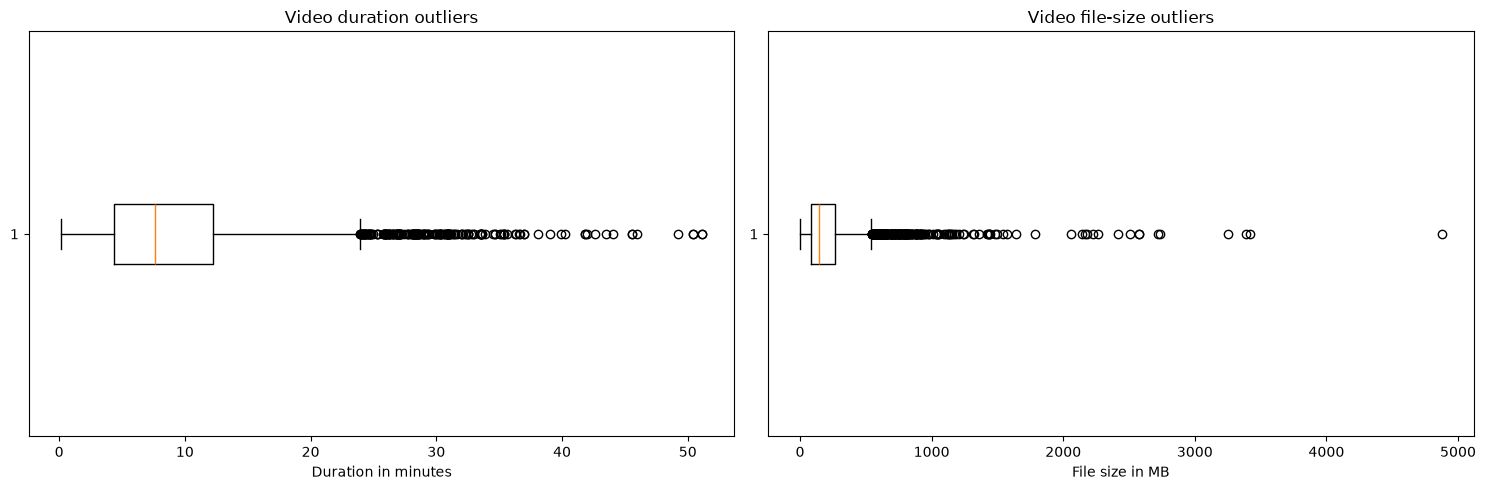

Chart saved: '/home/ganand/Documents/Youtube-Persistence/Code/Data Analysis/Results/video_outliers.png'


In [31]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].boxplot(
    inventory["duration_minutes"].dropna(),
    orientation="horizontal",
)
axes[0].set_title("Video duration outliers")
axes[0].set_xlabel("Duration in minutes")

axes[1].boxplot(
    inventory["size_mb"].dropna(),
    orientation="horizontal",
)
axes[1].set_title("Video file-size outliers")
axes[1].set_xlabel("File size in MB")

plt.tight_layout()

OUTLIER_CHART = OUTPUT_DIR / "video_outliers.png"
plt.savefig(OUTLIER_CHART, dpi=200, bbox_inches="tight")
plt.show()

print("Chart saved:", repr(str(OUTLIER_CHART)))

DATA STORAGE ANALYSIS

In [32]:
total_duration_seconds = (
    inventory["duration_seconds"].fillna(0).sum()
)

total_duration_hours = total_duration_seconds / 3600

sampling_options = pd.DataFrame({
    "strategy": [
        "1 frame every 30 seconds",
        "1 frame every 10 seconds",
        "1 frame every 5 seconds",
        "1 frame every 2 seconds",
        "1 frame every second",
    ],
    "sampling_rate_fps": [
        1 / 30,
        1 / 10,
        1 / 5,
        1 / 2,
        1,
    ],
})

sampling_options["estimated_frames"] = (
    total_duration_seconds
    * sampling_options["sampling_rate_fps"]
).round().astype("int64")

# Assumption: an extracted JPEG frame averages 150 KB.
average_frame_size_kb = 150

sampling_options["estimated_storage_gb"] = (
    sampling_options["estimated_frames"]
    * average_frame_size_kb
    / 1024
    / 1024
).round(2)

# Estimate model inference time at 20 sampled frames per second.
model_speed_fps = 20

sampling_options["estimated_model_hours"] = (
    sampling_options["estimated_frames"]
    / model_speed_fps
    / 3600
).round(2)

display(sampling_options)

,strategy,sampling_rate_fps,estimated_frames,estimated_storage_gb,estimated_model_hours
0,1 frame every 30 seconds,0.033333,55125,7.89,0.77
1,1 frame every 10 seconds,0.100000,165375,23.66,2.30
2,1 frame every 5 seconds,0.200000,330750,47.31,4.59
3,1 frame every 2 seconds,0.500000,826874,118.29,11.48
4,1 frame every second,1.000000,1653749,236.57,22.97


In [33]:
audio_bytes_per_second = 16_000 * 2

estimated_audio_gb = (
    total_duration_seconds
    * audio_bytes_per_second
    / 1024**3
)

print(f"Total video duration: {total_duration_hours:,.2f} hours")
print(
    "Estimated 16 kHz WAV storage:",
    f"{estimated_audio_gb:,.2f} GB",
)

Total video duration: 459.37 hours
Estimated 16 kHz WAV storage: 49.29 GB


In [34]:
known_frame_count = inventory["frame_count"].fillna(0).sum()

print(f"Total reported source frames: {known_frame_count:,.0f}")

for processing_speed in [10, 25, 50, 100]:
    estimated_hours = (
        known_frame_count
        / processing_speed
        / 3600
    )

    print(
        f"At {processing_speed} frames/second: "
        f"{estimated_hours:,.2f} processing hours"
    )

Total reported source frames: 55,494,893
At 10 frames/second: 1,541.52 processing hours
At 25 frames/second: 616.61 processing hours
At 50 frames/second: 308.30 processing hours
At 100 frames/second: 154.15 processing hours


In [35]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / 1024**3,
            2,
        ),
        "GB",
    )

PyTorch version: 2.14.1+cu130
CUDA available: False


/home/ganand/miniconda3/envs/yp/lib/python3.14/site-packages/torch/cuda/__init__.py:228: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12020). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


In [36]:
codec_plan = (
    inventory.assign(
        codec_clean=(
            inventory["codec"]
            .fillna("Unknown")
            .astype(str)
            .str.upper()
        )
    )
    .groupby("codec_clean", as_index=False)
    .agg(video_count=("filename", "size"))
    .sort_values("video_count", ascending=False)
)

codec_plan["percentage"] = (
    codec_plan["video_count"]
    / codec_plan["video_count"].sum()
    * 100
).round(2)

display(codec_plan)

,codec_clean,video_count,percentage
1,H264,2530,88.09
2,VP90,228,7.94
0,AV01,114,3.97


In [37]:
PROCESSING_PLAN_CSV = (
    OUTPUT_DIR / "visual_processing_plan.csv"
)

sampling_options.to_csv(
    PROCESSING_PLAN_CSV,
    index=False,
)

print("Saved:", PROCESSING_PLAN_CSV.exists())
print("Path:", repr(str(PROCESSING_PLAN_CSV)))

Saved: True
Path: '/home/ganand/Documents/Youtube-Persistence/Code/Data Analysis/Results/visual_processing_plan.csv'


TRANSCRIPT ANALYSIS

In [38]:
# ============================================================
# FINAL STEP 6 PIPELINE — ALL CREATORS
# ============================================================

from pathlib import Path
from collections import defaultdict
from difflib import SequenceMatcher

import hashlib
import html
import re
import unicodedata

import pandas as pd
from IPython.display import display
from tqdm.auto import tqdm


# ============================================================
# 1. PATHS
# ============================================================

DATA_ROOT = Path(
    "/mnt/storage/data/youtube/updated_75users/daily"
)

OUTPUT_DIR = (
    Path("/home/ganand/Documents/Youtube-Persistence/Code")
    / "Data Analysis/Results"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

VIDEO_INVENTORY_CSV = (
    OUTPUT_DIR
    / "all_creators_video_inventory.csv"
)

if not DATA_ROOT.is_dir():
    raise FileNotFoundError(
        f"Dataset directory not found: {DATA_ROOT}"
    )

if not VIDEO_INVENTORY_CSV.exists():
    raise FileNotFoundError(
        "The video inventory is missing. Rerun the video "
        f"inventory step first: {VIDEO_INVENTORY_CSV}"
    )

video_inventory = pd.read_csv(
    VIDEO_INVENTORY_CSV
)


# ============================================================
# 2. HELPER FUNCTIONS
# ============================================================

YOUTUBE_ID_PATTERN = re.compile(
    r"\[([A-Za-z0-9_-]{11})\]"
)


def read_transcript(path):
    return path.read_text(
        encoding="utf-8",
        errors="replace",
    ).strip()


def extract_youtube_id(filename):
    match = YOUTUBE_ID_PATTERN.search(
        str(filename)
    )

    return match.group(1) if match else None


def extract_day_number(filename):
    matches = re.findall(
        r"(?i)(?:^|[^a-z])day[\s_-]*(\d{1,3})\b",
        Path(str(filename)).stem,
    )

    return int(matches[-1]) if matches else None


def normalize_creator_name(creator):
    creator = html.unescape(str(creator))

    creator = unicodedata.normalize(
        "NFKC",
        creator,
    ).lower()

    creator = re.sub(
        r"[\W_]+",
        " ",
        creator,
    )

    return re.sub(
        r"\s+",
        " ",
        creator,
    ).strip()


def normalize_creator_title(filename, creator):
    title = html.unescape(str(filename))

    title = unicodedata.normalize(
        "NFKC",
        title,
    )

    title = Path(title).stem.lower()

    # Remove a YouTube ID such as [UCFMgld_adA].
    title = YOUTUBE_ID_PATTERN.sub(
        " ",
        title,
    )

    # Remove trailing language markers from *.en.txt.
    title = re.sub(
        r"(?:[\s._-]+en)$",
        " ",
        title,
    )

    # Remove prefixes such as:
    # Day_01 -
    # Day_01 - 03 -
    title = re.sub(
        r"^\s*day[\s_-]*\d{1,3}"
        r"(?:\s*[-_]\s*\d{1,3})?"
        r"\s*[-_]\s*",
        " ",
        title,
    )

    # Remove prefixes such as:
    # 001_
    # 001_02_20241003_
    # 55 -
    title = re.sub(
        r"^\s*(?:\d{1,8}[\s_.-]+){1,4}",
        " ",
        title,
    )

    # Remove YYYYMMDD dates.
    title = re.sub(
        r"\b(?:19|20)\d{6}\b",
        " ",
        title,
    )

    title = re.sub(
        r"[\W_]+",
        " ",
        title,
    )

    title = re.sub(
        r"\s+",
        " ",
        title,
    ).strip()

    # Remove creator name when it is a title prefix.
    creator_name = normalize_creator_name(
        creator
    )

    if (
        creator_name
        and title.startswith(
            creator_name + " "
        )
    ):
        title = title[
            len(creator_name):
        ].strip()

    return title


def title_similarity(first, second):
    if not first or not second:
        return 0.0

    return SequenceMatcher(
        None,
        first,
        second,
    ).ratio()


def normalize_content(text):
    return re.sub(
        r"\s+",
        " ",
        text,
    ).strip()


def calculate_content_hash(text):
    normalized = normalize_content(text)

    return hashlib.sha256(
        normalized.encode("utf-8")
    ).hexdigest()


def extract_words(text):
    return re.findall(
        r"\b[^\W\d_]+(?:'[^\W\d_]+)?\b",
        text.lower(),
        flags=re.UNICODE,
    )


def choose_canonical_file(paths):
    # Prefer filenames containing a YouTube ID.
    return sorted(
        paths,
        key=lambda path: (
            0
            if extract_youtube_id(path.name)
            else 1,
            path.name.lower(),
        ),
    )[0]


# ============================================================
# 3. DISCOVER AND DEDUPLICATE TRANSCRIPTS
# ============================================================

transcript_rows = []
source_rows = []

creator_directories = sorted(
    path
    for path in DATA_ROOT.iterdir()
    if path.is_dir()
)

for creator_directory in tqdm(
    creator_directories,
    desc="Reading transcripts",
):
    creator = creator_directory.name

    punctuated_directory = (
        creator_directory
        / "txt_punctuated"
    )

    plain_directory = (
        creator_directory
        / "txt"
    )

    punctuated_files = (
        sorted(
            path
            for path
            in punctuated_directory.rglob(
                "*.txt"
            )
            if path.is_file()
        )
        if punctuated_directory.is_dir()
        else []
    )

    plain_files = (
        sorted(
            path
            for path
            in plain_directory.rglob("*.txt")
            if path.is_file()
        )
        if plain_directory.is_dir()
        else []
    )

    # Prefer punctuated transcripts.
    if punctuated_files:
        selected_files = punctuated_files
        selected_source = "txt_punctuated"
    else:
        selected_files = plain_files
        selected_source = "txt"

    source_rows.append({
        "creator": creator,
        "selected_source": selected_source,
        "selected_file_count": len(
            selected_files
        ),
        "punctuated_file_count": len(
            punctuated_files
        ),
        "plain_file_count": len(
            plain_files
        ),
    })

    content_groups = defaultdict(list)
    text_cache = {}

    for transcript_path in selected_files:
        text = read_transcript(
            transcript_path
        )

        text_cache[transcript_path] = text
        normalized_text = normalize_content(
            text
        )

        # Do not combine unrelated empty files.
        if normalized_text:
            group_key = calculate_content_hash(
                text
            )
        else:
            group_key = (
                f"empty:{transcript_path}"
            )

        content_groups[group_key].append(
            transcript_path
        )

    # Remove content-identical duplicates.
    for duplicate_group in (
        content_groups.values()
    ):
        canonical_path = (
            choose_canonical_file(
                duplicate_group
            )
        )

        text = text_cache[canonical_path]
        words = extract_words(text)

        sentences = [
            sentence.strip()
            for sentence in re.split(
                r"[.!?]+",
                text,
            )
            if sentence.strip()
        ]

        word_count = len(words)
        unique_word_count = len(set(words))
        sentence_count = len(sentences)

        transcript_rows.append({
            "creator": creator,
            "transcript_filename": (
                canonical_path.name
            ),
            "transcript_path": str(
                canonical_path
            ),
            "transcript_source": (
                selected_source
            ),
            "youtube_id": (
                extract_youtube_id(
                    canonical_path.name
                )
            ),
            "day_number": (
                extract_day_number(
                    canonical_path.name
                )
            ),
            "normalized_title": (
                normalize_creator_title(
                    canonical_path.name,
                    creator,
                )
            ),
            "identical_duplicates_removed": (
                len(duplicate_group) - 1
            ),
            "duplicate_filenames": " | ".join(
                path.name
                for path in duplicate_group
                if path != canonical_path
            ),
            "character_count": len(text),
            "word_count": word_count,
            "unique_word_count": (
                unique_word_count
            ),
            "sentence_count": sentence_count,
            "average_words_per_sentence": (
                round(
                    word_count / sentence_count,
                    2,
                )
                if sentence_count > 0
                else None
            ),
            "lexical_diversity": (
                round(
                    unique_word_count
                    / word_count,
                    4,
                )
                if word_count > 0
                else None
            ),
            "empty_transcript": (
                word_count == 0
            ),
        })

transcripts = pd.DataFrame(
    transcript_rows
)

transcript_sources = pd.DataFrame(
    source_rows
)


# ============================================================
# 4. COLLAPSE LANGUAGE VARIANTS
# ============================================================

with_day = transcripts.loc[
    transcripts["day_number"].notna()
].copy()

without_day = transcripts.loc[
    transcripts["day_number"].isna()
].copy()

semantic_columns = [
    "creator",
    "day_number",
    "normalized_title",
]

with_day["semantic_variant_count"] = (
    with_day.groupby(
        semantic_columns
    )["transcript_filename"].transform(
        "size"
    )
)

# Prefer the most complete transcript variant.
with_day = (
    with_day.sort_values(
        "word_count",
        ascending=False,
    )
    .drop_duplicates(
        subset=semantic_columns,
        keep="first",
    )
)

without_day["semantic_variant_count"] = 1

transcripts = pd.concat(
    [with_day, without_day],
    ignore_index=True,
)

transcripts = (
    transcripts.reset_index(drop=True)
    .reset_index(names="transcript_id")
)


# ============================================================
# 5. PREPARE VIDEO RECORDS
# ============================================================

videos = (
    video_inventory.copy()
    .reset_index(drop=True)
    .reset_index(names="video_id")
)

videos["youtube_id"] = (
    videos["filename"]
    .astype(str)
    .apply(extract_youtube_id)
)

videos["day_number"] = (
    videos["filename"]
    .astype(str)
    .apply(extract_day_number)
)

videos["normalized_title"] = (
    videos.apply(
        lambda row: normalize_creator_title(
            row["filename"],
            row["creator"],
        ),
        axis=1,
    )
)


# ============================================================
# 6. MATCH TRANSCRIPTS TO VIDEOS
# ============================================================

match_rows = []
unmatched_video_rows = []
unmatched_transcript_rows = []


def create_match(
    video,
    transcript,
    method,
    confidence,
):
    duration = video["duration_minutes"]

    word_density = (
        transcript["word_count"] / duration
        if pd.notna(duration)
        and duration > 0
        else None
    )

    return {
        "creator": video["creator"],
        "video_id": video["video_id"],
        "video_filename": (
            video["filename"]
        ),
        "video_relative_path": (
            video["relative_path"]
        ),
        "duration_minutes": duration,
        "resolution": video["resolution"],
        "fps": video["fps"],
        "codec": video["codec"],
        "transcript_id": (
            transcript["transcript_id"]
        ),
        "transcript_filename": (
            transcript[
                "transcript_filename"
            ]
        ),
        "transcript_path": (
            transcript["transcript_path"]
        ),
        "match_method": method,
        "match_confidence": round(
            confidence,
            4,
        ),
        "words_per_video_minute": (
            round(word_density, 2)
            if word_density is not None
            else None
        ),
    }


all_creators = sorted(
    set(videos["creator"])
    | set(transcripts["creator"])
)

for creator in tqdm(
    all_creators,
    desc="Matching transcripts",
):
    creator_videos = (
        videos.loc[
            videos["creator"] == creator
        ]
        .to_dict("records")
    )

    creator_transcripts = (
        transcripts.loc[
            transcripts["creator"]
            == creator
        ]
        .to_dict("records")
    )

    remaining_videos = {
        row["video_id"]: row
        for row in creator_videos
    }

    remaining_transcripts = {
        row["transcript_id"]: row
        for row in creator_transcripts
    }

    def accept(
        video_id,
        transcript_id,
        method,
        score,
    ):
        video = remaining_videos.pop(
            video_id
        )

        transcript = (
            remaining_transcripts.pop(
                transcript_id
            )
        )

        match_rows.append(
            create_match(
                video,
                transcript,
                method,
                score,
            )
        )

    def match_unique_field(
        field,
        method,
        minimum_similarity=None,
    ):
        video_groups = defaultdict(list)
        transcript_groups = defaultdict(list)

        for video in remaining_videos.values():
            value = video[field]

            if pd.notna(value) and value != "":
                video_groups[value].append(
                    video["video_id"]
                )

        for transcript in (
            remaining_transcripts.values()
        ):
            value = transcript[field]

            if pd.notna(value) and value != "":
                transcript_groups[value].append(
                    transcript[
                        "transcript_id"
                    ]
                )

        pending = []

        for value in (
            set(video_groups)
            & set(transcript_groups)
        ):
            if (
                len(video_groups[value]) == 1
                and len(
                    transcript_groups[value]
                ) == 1
            ):
                video_id = video_groups[
                    value
                ][0]

                transcript_id = (
                    transcript_groups[
                        value
                    ][0]
                )

                video = remaining_videos[
                    video_id
                ]

                transcript = (
                    remaining_transcripts[
                        transcript_id
                    ]
                )

                score = title_similarity(
                    video["normalized_title"],
                    transcript[
                        "normalized_title"
                    ],
                )

                if (
                    minimum_similarity is None
                    or score
                    >= minimum_similarity
                ):
                    confidence = (
                        1.0
                        if method
                        in {
                            "youtube_id",
                            "normalized_title",
                        }
                        else score
                    )

                    pending.append(
                        (
                            video_id,
                            transcript_id,
                            confidence,
                        )
                    )

        for (
            video_id,
            transcript_id,
            confidence,
        ) in pending:
            if (
                video_id in remaining_videos
                and transcript_id
                in remaining_transcripts
            ):
                accept(
                    video_id,
                    transcript_id,
                    method,
                    confidence,
                )

    # Strong deterministic rules.
    match_unique_field(
        "youtube_id",
        "youtube_id",
    )

    match_unique_field(
        "normalized_title",
        "normalized_title",
    )

    match_unique_field(
        "day_number",
        "unique_day",
        minimum_similarity=0.60,
    )

    # Conservative mutual-best fuzzy matching.
    video_candidates = list(
        remaining_videos.values()
    )

    transcript_candidates = list(
        remaining_transcripts.values()
    )

    if (
        video_candidates
        and transcript_candidates
    ):
        scores = {}

        for video in video_candidates:
            for transcript in (
                transcript_candidates
            ):
                scores[
                    (
                        video["video_id"],
                        transcript[
                            "transcript_id"
                        ],
                    )
                ] = title_similarity(
                    video["normalized_title"],
                    transcript[
                        "normalized_title"
                    ],
                )

        video_best = {}

        for video in video_candidates:
            ranked = sorted(
                [
                    (
                        transcript[
                            "transcript_id"
                        ],
                        scores[
                            (
                                video["video_id"],
                                transcript[
                                    "transcript_id"
                                ],
                            )
                        ],
                    )
                    for transcript
                    in transcript_candidates
                ],
                key=lambda item: item[1],
                reverse=True,
            )

            video_best[
                video["video_id"]
            ] = {
                "transcript_id": ranked[0][0],
                "score": ranked[0][1],
                "margin": (
                    ranked[0][1]
                    - (
                        ranked[1][1]
                        if len(ranked) > 1
                        else 0
                    )
                ),
            }

        transcript_best = {}

        for transcript in (
            transcript_candidates
        ):
            ranked = sorted(
                [
                    (
                        video["video_id"],
                        scores[
                            (
                                video["video_id"],
                                transcript[
                                    "transcript_id"
                                ],
                            )
                        ],
                    )
                    for video
                    in video_candidates
                ],
                key=lambda item: item[1],
                reverse=True,
            )

            transcript_best[
                transcript["transcript_id"]
            ] = {
                "video_id": ranked[0][0],
                "score": ranked[0][1],
                "margin": (
                    ranked[0][1]
                    - (
                        ranked[1][1]
                        if len(ranked) > 1
                        else 0
                    )
                ),
            }

        fuzzy_pending = []

        for (
            video_id,
            result,
        ) in video_best.items():
            transcript_id = result[
                "transcript_id"
            ]

            reverse = transcript_best[
                transcript_id
            ]

            if (
                reverse["video_id"]
                == video_id
                and result["score"] >= 0.88
                and result["margin"] >= 0.08
                and reverse["margin"] >= 0.08
            ):
                fuzzy_pending.append(
                    (
                        video_id,
                        transcript_id,
                        result["score"],
                    )
                )

        fuzzy_pending = sorted(
            fuzzy_pending,
            key=lambda item: item[2],
            reverse=True,
        )

        for (
            video_id,
            transcript_id,
            score,
        ) in fuzzy_pending:
            if (
                video_id in remaining_videos
                and transcript_id
                in remaining_transcripts
            ):
                accept(
                    video_id,
                    transcript_id,
                    "fuzzy_title",
                    score,
                )

    # Preserve all unresolved records.
    for video in remaining_videos.values():
        best_name = None
        best_score = 0.0

        for transcript in (
            remaining_transcripts.values()
        ):
            score = title_similarity(
                video["normalized_title"],
                transcript[
                    "normalized_title"
                ],
            )

            if score > best_score:
                best_score = score
                best_name = transcript[
                    "transcript_filename"
                ]

        unmatched_video_rows.append({
            "creator": creator,
            "video_filename": (
                video["filename"]
            ),
            "video_relative_path": (
                video["relative_path"]
            ),
            "suggested_transcript": (
                best_name
            ),
            "suggestion_score": round(
                best_score,
                4,
            ),
        })

    for transcript in (
        remaining_transcripts.values()
    ):
        unmatched_transcript_rows.append({
            "creator": creator,
            "transcript_id": (
                transcript["transcript_id"]
            ),
            "transcript_filename": (
                transcript[
                    "transcript_filename"
                ]
            ),
            "transcript_path": (
                transcript["transcript_path"]
            ),
            "word_count": (
                transcript["word_count"]
            ),
        })


# ============================================================
# 7. BUILD FINAL LANGUAGE CORPUS
# ============================================================

matches = pd.DataFrame(match_rows)

unmatched_videos = pd.DataFrame(
    unmatched_video_rows
)

unmatched_transcripts = pd.DataFrame(
    unmatched_transcript_rows
)

video_links = matches[
    [
        "transcript_id",
        "video_id",
        "video_filename",
        "video_relative_path",
        "duration_minutes",
        "resolution",
        "fps",
        "codec",
        "match_method",
        "match_confidence",
        "words_per_video_minute",
    ]
].copy()

transcript_corpus = transcripts.merge(
    video_links,
    on="transcript_id",
    how="left",
)

transcript_corpus["matched_to_video"] = (
    transcript_corpus["video_id"].notna()
)


def classify_link(row):
    if not row["matched_to_video"]:
        return "Unlinked transcript"

    if row["match_method"] in {
        "youtube_id",
        "normalized_title",
    }:
        return "Strong video link"

    return "Video link requires review"


transcript_corpus["link_status"] = (
    transcript_corpus.apply(
        classify_link,
        axis=1,
    )
)


# ============================================================
# 8. CREATOR-LEVEL SUMMARY
# ============================================================

creator_language_summary = (
    transcript_corpus.groupby(
        "creator",
        as_index=False,
    )
    .agg(
        transcript_count=(
            "transcript_id",
            "size",
        ),
        matched_transcripts=(
            "matched_to_video",
            "sum",
        ),
        total_words=(
            "word_count",
            "sum",
        ),
        average_words=(
            "word_count",
            "mean",
        ),
        median_words=(
            "word_count",
            "median",
        ),
        average_lexical_diversity=(
            "lexical_diversity",
            "mean",
        ),
        empty_transcripts=(
            "empty_transcript",
            "sum",
        ),
    )
)

creator_language_summary[
    "unlinked_transcripts"
] = (
    creator_language_summary[
        "transcript_count"
    ]
    - creator_language_summary[
        "matched_transcripts"
    ]
)

creator_language_summary[
    "video_link_percentage"
] = (
    creator_language_summary[
        "matched_transcripts"
    ]
    / creator_language_summary[
        "transcript_count"
    ]
    * 100
).round(2)

creator_language_summary = (
    creator_language_summary.round(2)
    .sort_values(
        "transcript_count",
        ascending=False,
    )
)

video_creators = set(
    videos["creator"]
)

transcript_creators = set(
    transcript_corpus["creator"]
)

creators_without_transcripts = pd.DataFrame({
    "creator": sorted(
        video_creators
        - transcript_creators
    )
})

matches_for_review = (
    matches.loc[
        matches["match_method"].isin(
            ["unique_day", "fuzzy_title"]
        )
    ]
    .sort_values("match_confidence")
)


# ============================================================
# 9. SAVE FINAL STEP 6 OUTPUTS
# ============================================================

FINAL_FILES = {
    "corpus": (
        OUTPUT_DIR
        / "all_creators_transcript_analysis_corpus.csv"
    ),
    "language_summary": (
        OUTPUT_DIR
        / "all_creators_language_summary.csv"
    ),
    "matches": (
        OUTPUT_DIR
        / "all_creators_transcript_matches.csv"
    ),
    "matches_for_review": (
        OUTPUT_DIR
        / "all_creators_matches_for_review.csv"
    ),
    "unmatched_videos": (
        OUTPUT_DIR
        / "all_creators_unmatched_videos.csv"
    ),
    "unmatched_transcripts": (
        OUTPUT_DIR
        / "all_creators_unmatched_transcripts.csv"
    ),
    "creators_without_transcripts": (
        OUTPUT_DIR
        / "creators_without_transcripts.csv"
    ),
    "transcript_sources": (
        OUTPUT_DIR
        / "all_creators_transcript_sources.csv"
    ),
}

transcript_corpus.to_csv(
    FINAL_FILES["corpus"],
    index=False,
)

creator_language_summary.to_csv(
    FINAL_FILES["language_summary"],
    index=False,
)

matches.to_csv(
    FINAL_FILES["matches"],
    index=False,
)

matches_for_review.to_csv(
    FINAL_FILES["matches_for_review"],
    index=False,
)

unmatched_videos.to_csv(
    FINAL_FILES["unmatched_videos"],
    index=False,
)

unmatched_transcripts.to_csv(
    FINAL_FILES["unmatched_transcripts"],
    index=False,
)

creators_without_transcripts.to_csv(
    FINAL_FILES[
        "creators_without_transcripts"
    ],
    index=False,
)

transcript_sources.to_csv(
    FINAL_FILES["transcript_sources"],
    index=False,
)


# ============================================================
# 10. FINAL REPORT
# ============================================================

print("\nFINAL STEP 6 COMPLETE")
print("=" * 60)

print(
    "Canonical transcripts:",
    f"{len(transcript_corpus):,}",
)

print(
    "Linked to videos:",
    f"{transcript_corpus['matched_to_video'].sum():,}",
)

print(
    "Available for language analysis:",
    f"{len(transcript_corpus):,}",
)

print(
    "Creators with transcripts:",
    transcript_corpus[
        "creator"
    ].nunique(),
)

print(
    "Creators without transcripts:",
    len(creators_without_transcripts),
)

print(
    "Total transcript words:",
    f"{transcript_corpus['word_count'].sum():,.0f}",
)

print("\nLink status:")

display(
    transcript_corpus[
        "link_status"
    ].value_counts().to_frame(
        "transcripts"
    )
)

print("\nMatch methods:")

display(
    matches[
        "match_method"
    ].value_counts().to_frame(
        "matches"
    )
)

print("\nCreator language summary:")

display(
    creator_language_summary
)

print("\nFiles saved:")

for label, path in FINAL_FILES.items():
    print(f"{label}: {path}")

Reading transcripts:   0%|          | 0/70 [00:00<?, ?it/s]

Matching transcripts:   0%|          | 0/68 [00:00<?, ?it/s]


FINAL STEP 6 COMPLETE
Canonical transcripts: 1,516
Linked to videos: 703
Available for language analysis: 1,516
Creators with transcripts: 58
Creators without transcripts: 10
Total transcript words: 2,214,428

Link status:


,transcripts
link_status,
Unlinked transcript,813
Strong video link,489
Video link requires review,214



Match methods:


,matches
match_method,
normalized_title,489
unique_day,198
fuzzy_title,16



Creator language summary:


,creator,transcript_count,matched_transcripts,total_words,average_words,median_words,average_lexical_diversity,empty_transcripts,unlinked_transcripts,video_link_percentage
22,Evan Merger,99,10,54659,552.11,277.0,0.46,0,89,10.10
45,RosetheLourdes,99,50,232173,2345.18,2241.0,0.28,0,49,50.51
10,Baby J,84,46,170191,2026.08,1974.5,0.29,0,38,54.76
0,80 vlogs,76,51,157415,2071.25,2063.0,0.25,0,25,67.11
17,Chris Guerra,76,54,315245,4147.96,4001.0,0.20,0,22,71.05
14,Bradley Macdonald,75,32,21473,286.31,269.0,0.49,0,43,42.67
26,JohansenFF,74,40,27848,376.32,299.5,0.47,0,34,54.05
19,Dasia Sade,74,40,96900,1309.46,1091.5,0.35,0,34,54.05
25,Jess Kaplan,73,17,80550,1103.42,828.0,0.37,0,56,23.29
6,Angelica,71,71,46761,658.61,622.0,0.40,0,0,100.00



Files saved:
corpus: /home/ganand/Documents/Youtube-Persistence/Code/Data Analysis/Results/all_creators_transcript_analysis_corpus.csv
language_summary: /home/ganand/Documents/Youtube-Persistence/Code/Data Analysis/Results/all_creators_language_summary.csv
matches: /home/ganand/Documents/Youtube-Persistence/Code/Data Analysis/Results/all_creators_transcript_matches.csv
matches_for_review: /home/ganand/Documents/Youtube-Persistence/Code/Data Analysis/Results/all_creators_matches_for_review.csv
unmatched_videos: /home/ganand/Documents/Youtube-Persistence/Code/Data Analysis/Results/all_creators_unmatched_videos.csv
unmatched_transcripts: /home/ganand/Documents/Youtube-Persistence/Code/Data Analysis/Results/all_creators_unmatched_transcripts.csv
creators_without_transcripts: /home/ganand/Documents/Youtube-Persistence/Code/Data Analysis/Results/creators_without_transcripts.csv
transcript_sources: /home/ganand/Documents/Youtube-Persistence/Code/Data Analysis/Results/all_creators_transcript_

Discovering videos:   0%|          | 0/70 [00:00<?, ?it/s]

Creators with videos: 68

Selected users:
- RosetheLourdes: 114 videos
- What Rissa Knows: 105 videos
- Matt Svatos: 102 videos
- BEEF1776: 99 videos
- Jake Bender: 94 videos


Reading RosetheLourdes:   0%|          | 0/114 [00:00<?, ?it/s]

Reading What Rissa Knows:   0%|          | 0/105 [00:00<?, ?it/s]

Reading Matt Svatos:   0%|          | 0/102 [00:00<?, ?it/s]

Reading BEEF1776:   0%|          | 0/99 [00:00<?, ?it/s]

Reading Jake Bender:   0%|          | 0/94 [00:00<?, ?it/s]

,creator,video_count,total_duration_hours,average_minutes,median_minutes,standard_deviation_minutes,shortest_video_minutes,longest_video_minutes,coefficient_of_variation
0,BEEF1776,99,26.80,16.24,14.50,6.18,6.59,30.40,0.38
3,RosetheLourdes,114,29.67,15.61,14.97,6.37,2.20,30.06,0.41
4,What Rissa Knows,105,15.12,8.64,8.38,0.72,8.00,10.99,0.08
2,Matt Svatos,102,13.43,7.90,7.59,2.51,4.06,15.30,0.32
1,Jake Bender,94,11.26,7.19,6.47,3.34,3.04,18.35,0.46


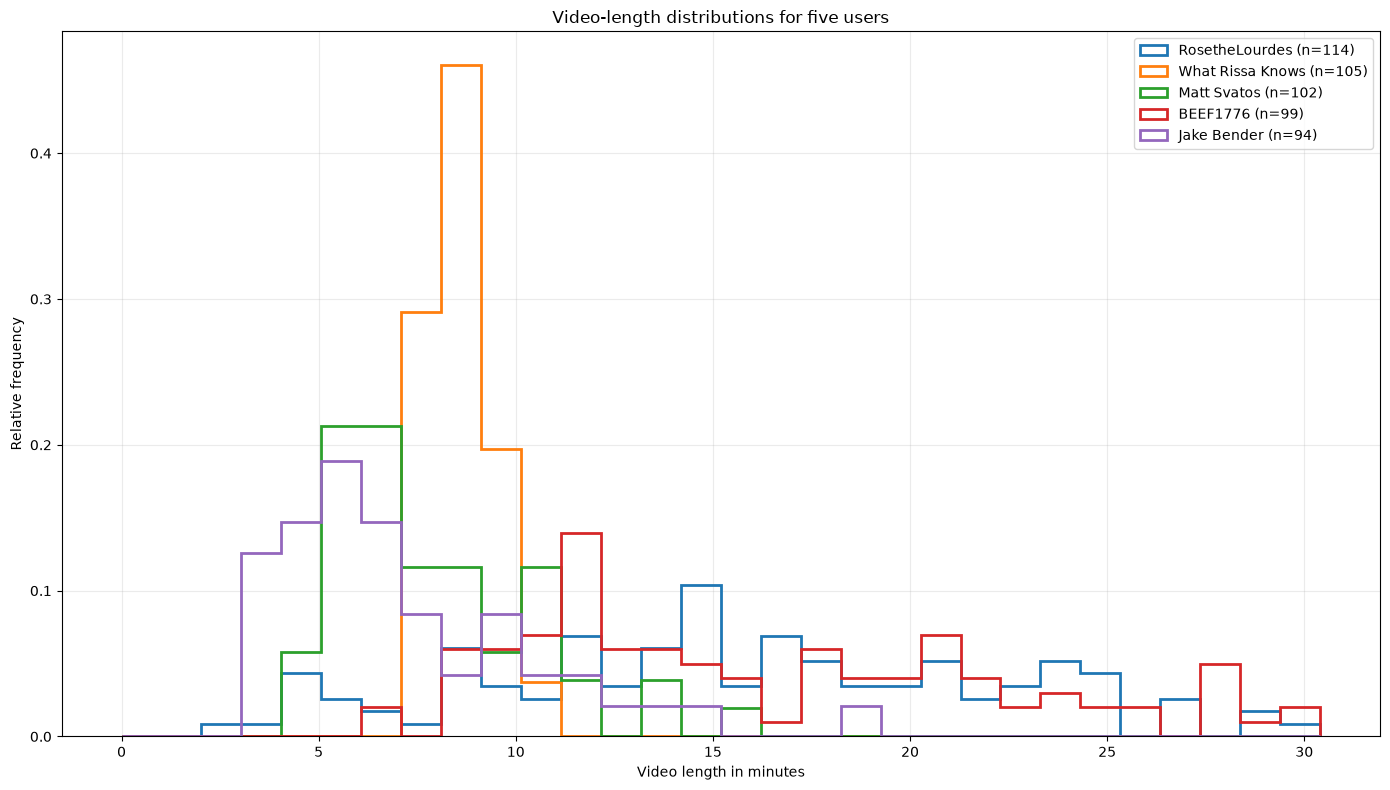


MVP complete
Videos discovered: 514
Valid durations: 514
Metadata failures: 0

Saved files:
'/home/ganand/Documents/Youtube-Persistence/Code/Data Analysis/Results/five_user_video_lengths.csv'
'/home/ganand/Documents/Youtube-Persistence/Code/Data Analysis/Results/five_user_video_length_summary.csv'
'/home/ganand/Documents/Youtube-Persistence/Code/Data Analysis/Results/five_user_video_length_histogram.png'


In [39]:
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from tqdm.auto import tqdm


DATA_ROOT = Path(
    "/mnt/storage/data/youtube/updated_75users/daily"
)

OUTPUT_DIR = (
    Path("/home/ganand/Documents/Youtube-Persistence/Code")
    / "Data Analysis"
    / "Results"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

if not DATA_ROOT.is_dir():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATA_ROOT}"
    )


# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

VIDEO_EXTENSIONS = {
    ".mp4",
    ".mov",
    ".avi",
    ".mkv",
    ".webm",
    ".m4v",
    ".mpeg",
    ".mpg",
}

# Set this to a list of five names if you want specific users.
# Leave it as None to select the five users with the most videos.
SELECTED_USERS = None

if hasattr(cv2, "setLogLevel"):
    cv2.setLogLevel(0)


videos_by_creator = {}

creator_directories = sorted(
    path
    for path in DATA_ROOT.iterdir()
    if path.is_dir()
)

for creator_directory in tqdm(
    creator_directories,
    desc="Discovering videos",
):
    mp4_directory = creator_directory / "mp4"

    if not mp4_directory.is_dir():
        continue

    video_files = sorted(
        path
        for path in mp4_directory.rglob("*")
        if (
            path.is_file()
            and path.suffix.lower()
            in VIDEO_EXTENSIONS
        )
    )

    if video_files:
        videos_by_creator[
            creator_directory.name
        ] = video_files

print(
    "Creators with videos:",
    len(videos_by_creator),
)


if SELECTED_USERS is None:
    selected_users = [
        creator
        for creator, files
        in sorted(
            videos_by_creator.items(),
            key=lambda item: len(item[1]),
            reverse=True,
        )[:5]
    ]
else:
    selected_users = SELECTED_USERS

    if len(selected_users) != 5:
        raise ValueError(
            "SELECTED_USERS must contain exactly five names."
        )

    missing_users = [
        creator
        for creator in selected_users
        if creator not in videos_by_creator
    ]

    if missing_users:
        raise ValueError(
            f"Creator folders not found: {missing_users}"
        )

print("\nSelected users:")

for creator in selected_users:
    print(
        f"- {creator}: "
        f"{len(videos_by_creator[creator])} videos"
    )

def inspect_duration(creator, video_path):
    result = {
        "creator": creator,
        "filename": video_path.name,
        "relative_path": str(
            video_path.relative_to(DATA_ROOT)
        ),
        "duration_seconds": None,
        "duration_minutes": None,
        "fps": None,
        "frame_count": None,
        "metadata_readable": False,
        "error": None,
    }

    capture = None

    try:
        capture = cv2.VideoCapture(
            str(video_path)
        )

        if not capture.isOpened():
            result["error"] = (
                "OpenCV could not open the video"
            )
            return result

        fps = float(
            capture.get(cv2.CAP_PROP_FPS)
        )

        frame_count = int(
            capture.get(
                cv2.CAP_PROP_FRAME_COUNT
            )
        )

        if fps > 0 and frame_count > 0:
            duration_seconds = (
                frame_count / fps
            )

            result.update({
                "duration_seconds": round(
                    duration_seconds,
                    2,
                ),
                "duration_minutes": round(
                    duration_seconds / 60,
                    2,
                ),
                "fps": round(fps, 3),
                "frame_count": frame_count,
                "metadata_readable": True,
            })
        else:
            result["error"] = (
                "FPS or frame count is missing"
            )

    except Exception as exc:
        result["error"] = (
            f"{type(exc).__name__}: {exc}"
        )

    finally:
        if capture is not None:
            capture.release()

    return result


records = []

for creator in selected_users:
    creator_files = videos_by_creator[
        creator
    ]

    for video_path in tqdm(
        creator_files,
        desc=f"Reading {creator}",
    ):
        records.append(
            inspect_duration(
                creator,
                video_path,
            )
        )

five_user_videos = pd.DataFrame(
    records
)

valid_videos = five_user_videos.loc[
    five_user_videos[
        "duration_minutes"
    ].notna()
    & (
        five_user_videos[
            "duration_minutes"
        ] > 0
    )
].copy()

if valid_videos.empty:
    raise RuntimeError(
        "No valid video durations were found."
    )


duration_summary = (
    valid_videos.groupby(
        "creator",
        as_index=False,
    )
    .agg(
        video_count=(
            "filename",
            "count",
        ),
        total_duration_hours=(
            "duration_minutes",
            lambda values: values.sum() / 60,
        ),
        average_minutes=(
            "duration_minutes",
            "mean",
        ),
        median_minutes=(
            "duration_minutes",
            "median",
        ),
        standard_deviation_minutes=(
            "duration_minutes",
            "std",
        ),
        shortest_video_minutes=(
            "duration_minutes",
            "min",
        ),
        longest_video_minutes=(
            "duration_minutes",
            "max",
        ),
    )
)

duration_summary[
    "coefficient_of_variation"
] = (
    duration_summary[
        "standard_deviation_minutes"
    ]
    / duration_summary[
        "average_minutes"
    ]
)

numeric_columns = (
    duration_summary
    .select_dtypes(include="number")
    .columns
)

duration_summary[numeric_columns] = (
    duration_summary[
        numeric_columns
    ].round(2)
)

duration_summary = (
    duration_summary.sort_values(
        "average_minutes",
        ascending=False,
    )
)

display(duration_summary)


all_durations = valid_videos[
    "duration_minutes"
]

bins = np.linspace(
    0,
    all_durations.max(),
    31,
)

plt.figure(figsize=(14, 8))

for creator in selected_users:
    creator_durations = (
        valid_videos.loc[
            valid_videos["creator"]
            == creator,
            "duration_minutes",
        ]
    )

    if creator_durations.empty:
        continue

    plt.hist(
        creator_durations,
        bins=bins,
        histtype="step",
        linewidth=2,
        density=True,
        label=(
            f"{creator} "
            f"(n={len(creator_durations)})"
        ),
    )

plt.title(
    "Video-length distributions for five users"
)
plt.xlabel("Video length in minutes")
plt.ylabel("Relative frequency")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()


LENGTH_DATA_CSV = (
    OUTPUT_DIR
    / "five_user_video_lengths.csv"
)

SUMMARY_CSV = (
    OUTPUT_DIR
    / "five_user_video_length_summary.csv"
)

HISTOGRAM_PNG = (
    OUTPUT_DIR
    / "five_user_video_length_histogram.png"
)

five_user_videos.to_csv(
    LENGTH_DATA_CSV,
    index=False,
)

duration_summary.to_csv(
    SUMMARY_CSV,
    index=False,
)

plt.savefig(
    HISTOGRAM_PNG,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("\nMVP complete")
print("Videos discovered:", len(five_user_videos))
print("Valid durations:", len(valid_videos))
print(
    "Metadata failures:",
    five_user_videos[
        "duration_minutes"
    ].isna().sum(),
)

print("\nSaved files:")
print(repr(str(LENGTH_DATA_CSV)))
print(repr(str(SUMMARY_CSV)))
print(repr(str(HISTOGRAM_PNG)))